## Step 9 - Calibration of the final model

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    brier_score_loss, roc_auc_score, average_precision_score, precision_recall_curve
)

In [2]:
from features import load_data

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
X_dev, y_dev, X_test, y_test = load_data()

final_choice = json.load(open("results/final_choice.json"))
model_name = final_choice["model"]
pipeline = joblib.load("models/best_" + model_name + ".pkl")
print("Final model:", model_name)

Final model: lightgbm


In [4]:
def reliability_curve(y_true, y_prob, n_bins=10):
    # equal-width bins between 0 and 1, we skip the empty bins
    y_true = np.array(y_true)
    bins = np.linspace(0, 1, n_bins + 1)
    conf = []
    acc = []
    counts = []
    for m in range(n_bins):
        if m == n_bins - 1:
            in_bin = (y_prob >= bins[m]) & (y_prob <= bins[m + 1])
        else:
            in_bin = (y_prob >= bins[m]) & (y_prob < bins[m + 1])
        if in_bin.sum() > 0:
            conf.append(y_prob[in_bin].mean())   # mean predicted probability
            acc.append(y_true[in_bin].mean())    # observed frequency of y = 1
            counts.append(in_bin.sum())
    return np.array(conf), np.array(acc), np.array(counts)

In [5]:
def expected_calibration_error(y_true, y_prob, n_bins=10):
    conf, acc, counts = reliability_curve(y_true, y_prob, n_bins)
    return np.sum(counts / len(y_true) * np.abs(acc - conf))


def brier_score(y_true, y_prob):
    return np.mean((y_prob - np.array(y_true)) ** 2)

In [6]:
# ---------------- PART A : diagnostic ----------------
proba_test = pipeline.predict_proba(X_test)[:, 1]

conf, acc, counts = reliability_curve(y_test, proba_test)
bins_table = pd.DataFrame({"mean_predicted": conf, "observed_freq": acc, "n_points": counts,
                           "gap (pred - obs)": conf - acc})
print("\nReliability table (test set, 10 equal-width bins):")
print(bins_table.round(3).to_string(index=False))


Reliability table (test set, 10 equal-width bins):
 mean_predicted  observed_freq  n_points  gap (pred - obs)
          0.069          0.030      2791             0.039
          0.143          0.060      3290             0.084
          0.241          0.096      1333             0.145
          0.343          0.192       437             0.150
          0.446          0.294       269             0.153
          0.550          0.426       298             0.124
          0.647          0.447       257             0.200
          0.746          0.596       171             0.150
          0.853          0.701       177             0.153
          0.910          0.900        20             0.010


In [7]:
# check with sklearn
sk_acc, sk_conf = calibration_curve(y_test, proba_test, n_bins=10, strategy="uniform")
print("Same as sklearn calibration_curve:", np.allclose(conf, sk_conf) and np.allclose(acc, sk_acc))

print("\nBrier score (our function):", round(brier_score(y_test, proba_test), 5))
print("Brier score (sklearn)     :", round(brier_score_loss(y_test, proba_test), 5))
print("Brier score of a model that always predicts the base rate:",
      round(brier_score(y_test, np.full(len(y_test), y_dev.mean())), 5))
print("ECE (10 bins):", round(expected_calibration_error(y_test, proba_test), 5))
print("Mean predicted probability:", round(proba_test.mean(), 4), "| real positive rate:", round(y_test.mean(), 4))
if proba_test.mean() > y_test.mean():
    print("-> on average the model predicts too high probabilities (over-estimation)")
else:
    print("-> on average the model predicts too low probabilities (under-estimation)")

Same as sklearn calibration_curve: True

Brier score (our function): 0.09017
Brier score (sklearn)     : 0.09017
Brier score of a model that always predicts the base rate: 0.10331
ECE (10 bins): 0.09124
Mean predicted probability: 0.2082 | real positive rate: 0.117
-> on average the model predicts too high probabilities (over-estimation)


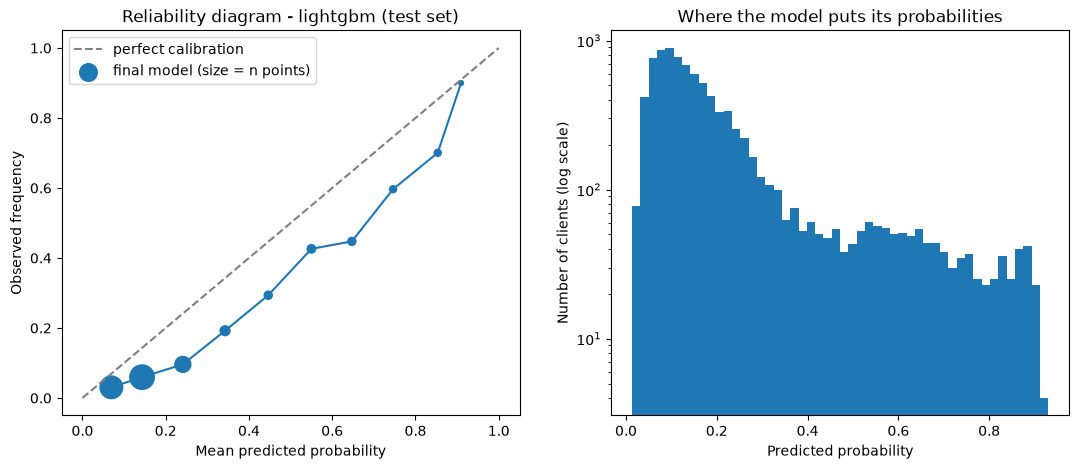

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
axes[0].plot(conf, acc, "-", color="tab:blue")
axes[0].scatter(conf, acc, s=counts / counts.max() * 300 + 10, color="tab:blue", label="final model (size = n points)")
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed frequency")
axes[0].set_title("Reliability diagram - " + model_name + " (test set)")
axes[0].legend()
axes[1].hist(proba_test, bins=50)
axes[1].set_yscale("log")
axes[1].set_xlabel("Predicted probability")
axes[1].set_ylabel("Number of clients (log scale)")
axes[1].set_title("Where the model puts its probabilities")
plt.savefig("plots/calibration_final_model.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# ---------------- PART B : recalibration ----------------
X_train, X_calib, y_train, y_calib = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=42
)
print("\nTrain:", X_train.shape, "| Calibration:", X_calib.shape)


Train: (28934, 15) | Calibration: (7234, 15)


In [10]:
base_model = clone(pipeline)
base_model.fit(X_train, y_train)

# FrozenEstimator = the base model is not retrained, only the calibration map is learned
platt = CalibratedClassifierCV(estimator=FrozenEstimator(base_model), method="sigmoid")
platt.fit(X_calib, y_calib)
isotonic = CalibratedClassifierCV(estimator=FrozenEstimator(base_model), method="isotonic")
isotonic.fit(X_calib, y_calib)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",FrozenEstimat...erbose=-1))]))
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary <n_jobs>` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
Name,Type,Value
"calibrated_classifiers_ calibrated_classifiers_: list (len() equal to cv or 1 if `ensemble=False`)The list of classifier and calibrator pairs.- When `ensemble=True`, `n_cv` fitted `estimator` and calibrator pairs. `n_cv` is the number of cross-validation folds.- When `ensemble=False`, the `estimator`, fitted on all the data, and fitted calibrator... versionchanged:: 0.24 Single calibrated classifier case when `ensemble=False`.",list,[<sklearn.cali...t 0x11dc401d0>]


In [11]:
probas = {
    "raw (trained on 80% dev)": base_model.predict_proba(X_test)[:, 1],
    "Platt (sigmoid)": platt.predict_proba(X_test)[:, 1],
    "isotonic": isotonic.predict_proba(X_test)[:, 1],
}

In [12]:
rows = []
for name in probas:
    rows.append({
        "model": name,
        "brier": brier_score(y_test, probas[name]),
        "ece": expected_calibration_error(y_test, probas[name]),
        "roc_auc": roc_auc_score(y_test, probas[name]),
        "pr_auc": average_precision_score(y_test, probas[name]),
        "mean_proba": probas[name].mean(),
    })
calib_df = pd.DataFrame(rows)
print("\n--- BEFORE / AFTER CALIBRATION (test set) --- real positive rate =", round(y_test.mean(), 4))
print(calib_df.round(4).to_string(index=False))
calib_df.to_csv("results/calibration_comparison.csv", index=False)


--- BEFORE / AFTER CALIBRATION (test set) --- real positive rate = 0.117
                   model  brier    ece  roc_auc  pr_auc  mean_proba
raw (trained on 80% dev) 0.0905 0.0899   0.8064  0.4642      0.2069
         Platt (sigmoid) 0.0804 0.0086   0.8064  0.4642      0.1151
                isotonic 0.0803 0.0075   0.8050  0.4441      0.1151


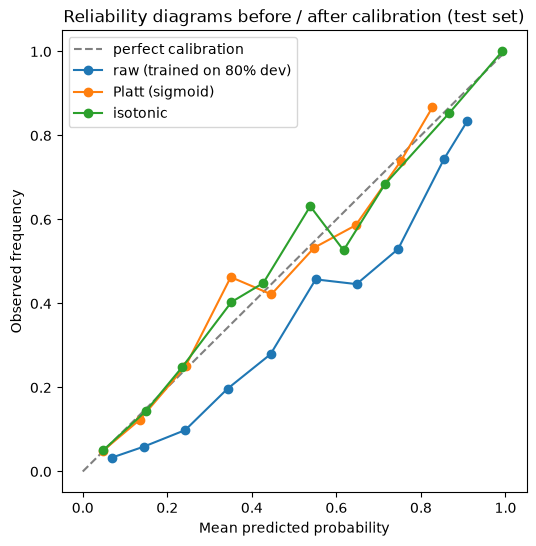

In [13]:
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
for name in probas:
    c, a, n = reliability_curve(y_test, probas[name])
    plt.plot(c, a, "o-", label=name)
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed frequency")
plt.title("Reliability diagrams before / after calibration (test set)")
plt.legend()
plt.savefig("plots/calibration_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
# we keep Platt scaling (session 7: simple and stable default, only 2 parameters)
# new threshold chosen on the calibration set (best F1), not on the test set
proba_calib = platt.predict_proba(X_calib)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_calib, proba_calib)
f1 = 2 * precision * recall / (precision + recall + 1e-10)
new_threshold = thresholds[np.argmax(f1[:-1])]
print("\nThreshold for the calibrated model (best F1 on the calibration set):", round(new_threshold, 3))


Threshold for the calibrated model (best F1 on the calibration set): 0.27


In [15]:
joblib.dump(platt, "models/final_calibrated_model.pkl")
with open("results/final_model_info.json", "w") as f:
    json.dump({"model": model_name, "calibration": "sigmoid (Platt)", "threshold": float(new_threshold)}, f, indent=4)
print("Saved models/final_calibrated_model.pkl and results/final_model_info.json")

Saved models/final_calibrated_model.pkl and results/final_model_info.json
